In [1]:
!pip install -q opencv-python-headless scikit-image

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import data

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

print("All libraries imported successfully!")

OpenCV version: 4.14.0
NumPy version: 2.4.6
All libraries imported successfully!


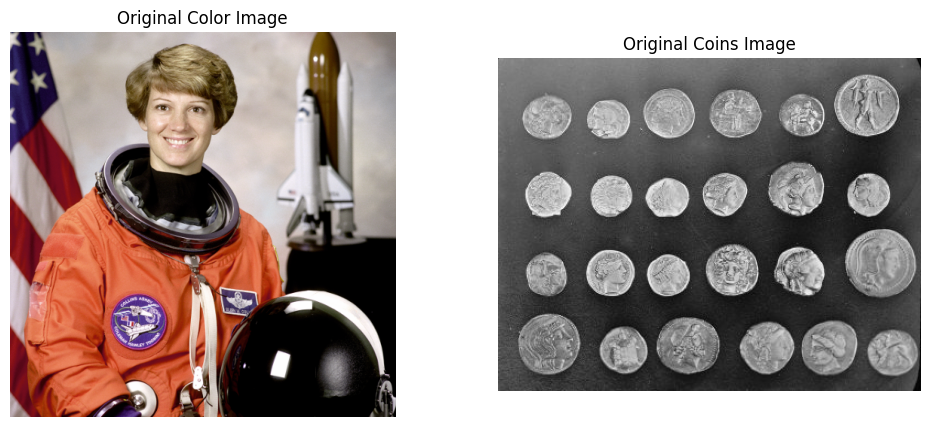

Color image shape: (512, 512, 3)
Coins image shape: (303, 384)


In [3]:
# Load sample images
color_image = data.astronaut()
coins_image = data.coins()

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(color_image)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(coins_image, cmap="gray")
plt.title("Original Coins Image")
plt.axis("off")

plt.show()

# Display image dimensions
print("Color image shape:", color_image.shape)
print("Coins image shape:", coins_image.shape)

Exercise 2: Color Space Conversion


1. RGB to BGR conversion
2. BGR to RGB conversion
3. RGB to Grayscale conversion


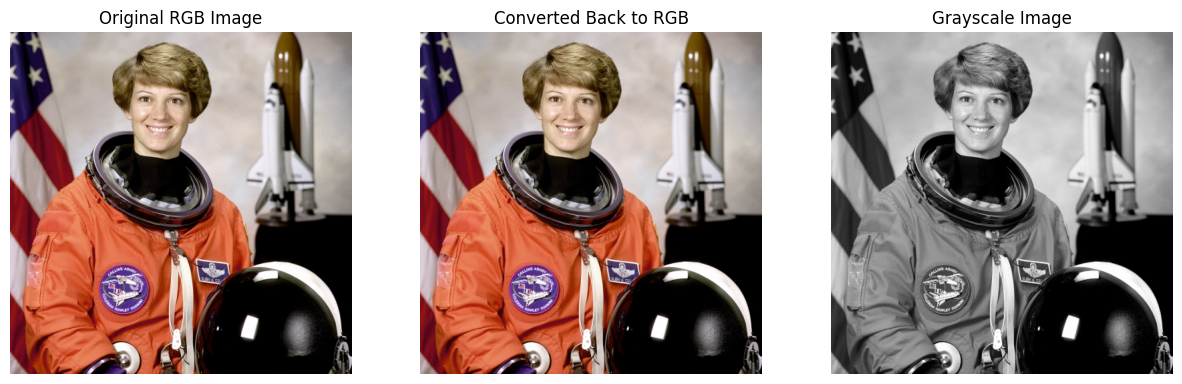

Original image shape: (512, 512, 3)
Grayscale image shape: (512, 512)


In [4]:
# RGB to BGR conversion
bgr_image = cv2.cvtColor(color_image, cv2.COLOR_RGB2BGR)

# BGR back to RGB
rgb_image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)

# RGB to Grayscale
gray_image = cv2.cvtColor(color_image, cv2.COLOR_RGB2GRAY)

# Display all images
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(color_image)
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(rgb_image)
plt.title("Converted Back to RGB")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

print("Original image shape:", color_image.shape)
print("Grayscale image shape:", gray_image.shape)

Exercise 3: Image Blurring Techniques

apply three image smoothing techniques:
1. Average Blur
2. Gaussian Blur
3. Median Blur


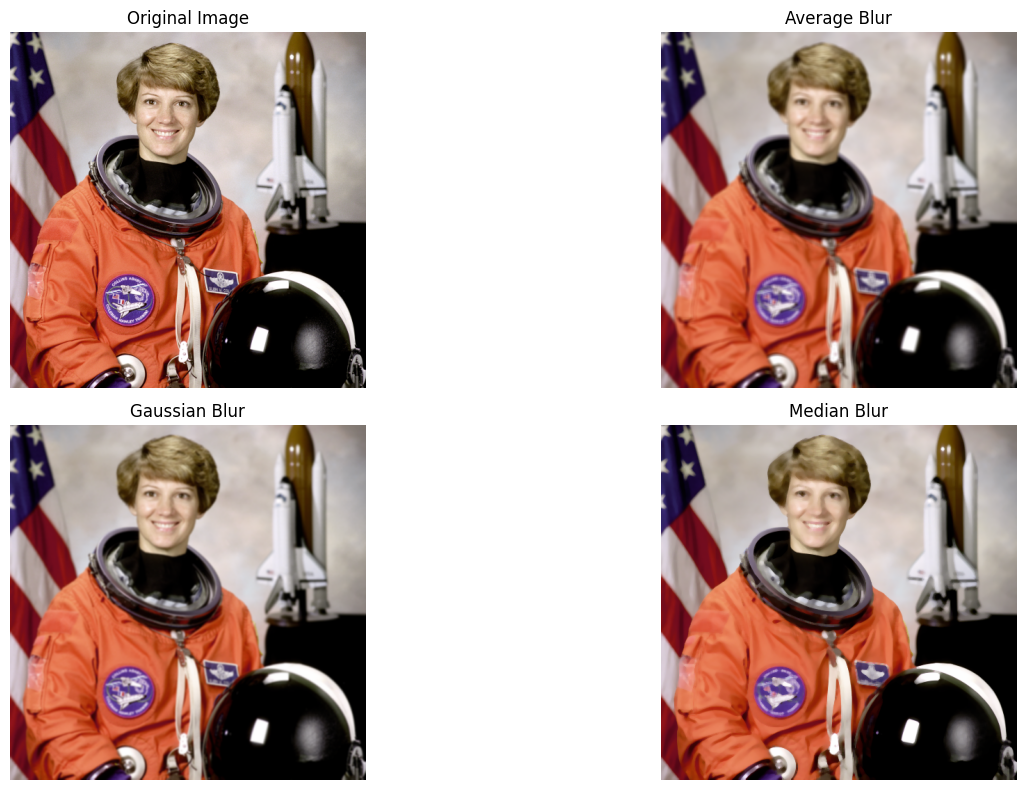

In [5]:
# Apply Average Blur
average_blur = cv2.blur(color_image, (5, 5))

# Apply Gaussian Blur
gaussian_blur = cv2.GaussianBlur(color_image, (5, 5), 0)

# Apply Median Blur
median_blur = cv2.medianBlur(color_image, 5)

# Display results
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(color_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(average_blur)
plt.title("Average Blur")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(gaussian_blur)
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(median_blur)
plt.title("Median Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

Exercise 4: Canny Edge Detection

edge detection using
the Canny Edge Detection algorithm:
1. Convert the original image to grayscale.
2. Apply Gaussian Blur to reduce noise.
3. Apply Canny edge detection.
4. Visualize the detected edges.

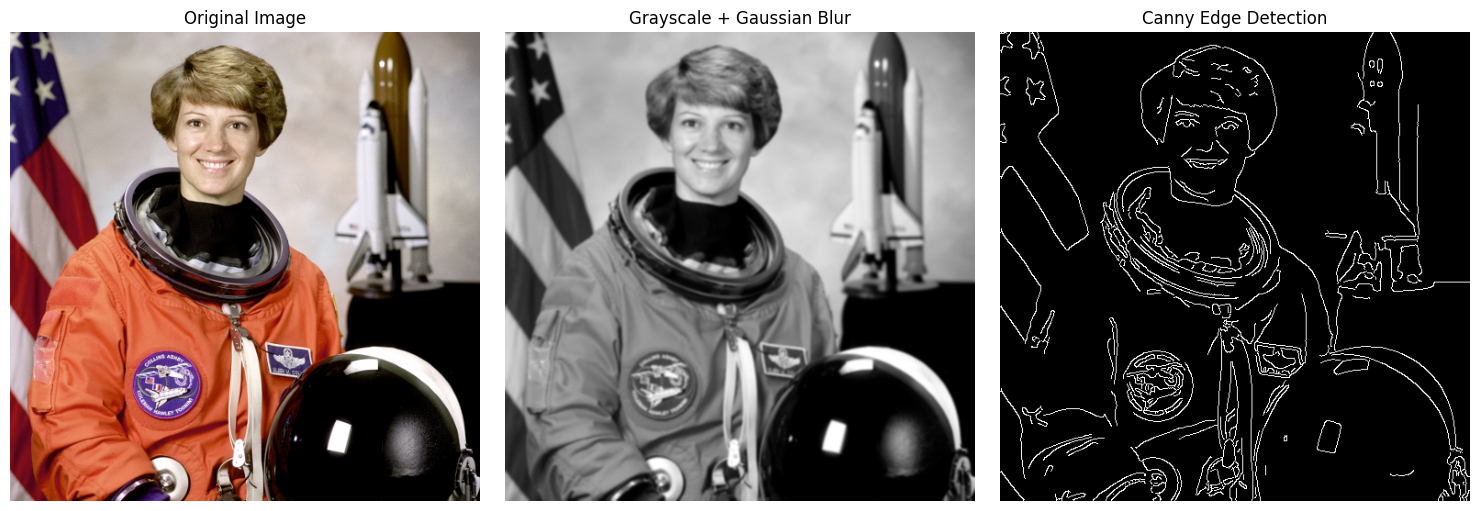

Edge image shape: (512, 512)
Detected edge pixels: 13654


In [6]:
# Step 1: Convert RGB image to grayscale
gray_image = cv2.cvtColor(color_image, cv2.COLOR_RGB2GRAY)

# Step 2: Apply Gaussian Blur
blurred_image = cv2.GaussianBlur(gray_image, (5, 5), 0)

# Step 3: Apply Canny Edge Detection
edges = cv2.Canny(blurred_image, 100, 200)

# Step 4: Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(color_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred_image, cmap="gray")
plt.title("Grayscale + Gaussian Blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Edge image shape:", edges.shape)
print("Detected edge pixels:", np.count_nonzero(edges))

Exercise 5: Contour Detection

detect object boundaries using OpenCV contours:
1. Load a grayscale coins image.
2. Apply Gaussian Blur.
3. Apply binary thresholding.
4. Detect external contours.
5. Draw the detected contours on the original image.

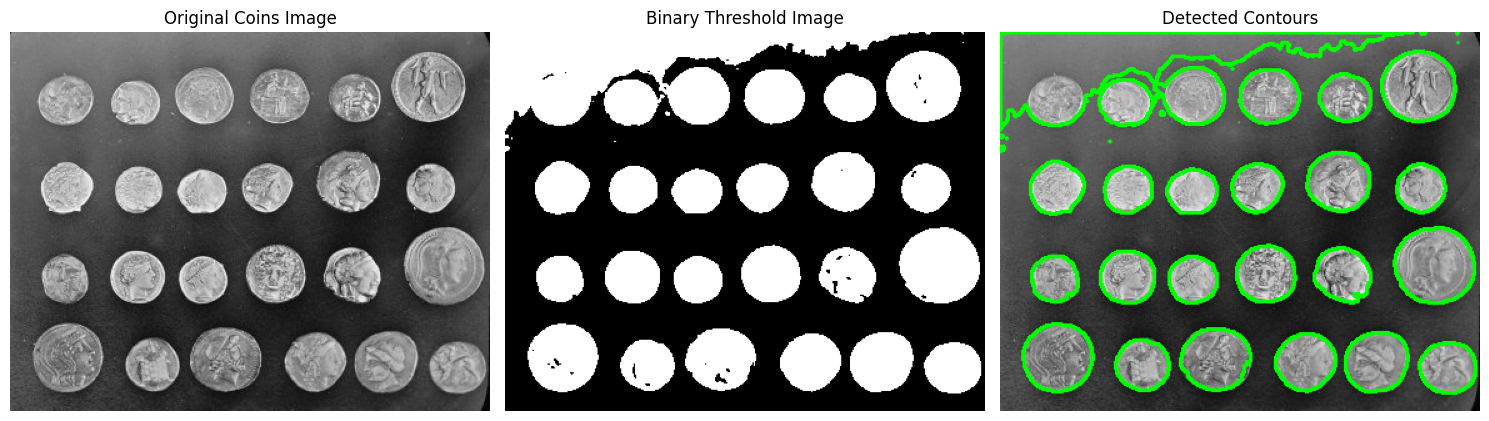

Total contours detected: 34


In [7]:
# Step 1: Load the coins image
coins = data.coins()

# Step 2: Apply Gaussian Blur
blurred_coins = cv2.GaussianBlur(coins, (5, 5), 0)

# Step 3: Apply binary thresholding using Otsu's method
_, threshold_image = cv2.threshold(
    blurred_coins,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Step 4: Find external contours
contours, hierarchy = cv2.findContours(
    threshold_image,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Step 5: Draw contours
contour_image = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)

cv2.drawContours(
    contour_image,
    contours,
    -1,
    (0, 255, 0),
    2
)

# Step 6: Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(coins, cmap="gray")
plt.title("Original Coins Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(threshold_image, cmap="gray")
plt.title("Binary Threshold Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(contour_image, cv2.COLOR_BGR2RGB))
plt.title("Detected Contours")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Total contours detected:", len(contours))

Exercise 6: Object Counting using Contours


count objects using contour detection:
1. Detect contours.
2. Filter contours based on area.
3. Remove unwanted noise.
4. Draw bounding boxes around detected objects.
5. Count the detected objects.

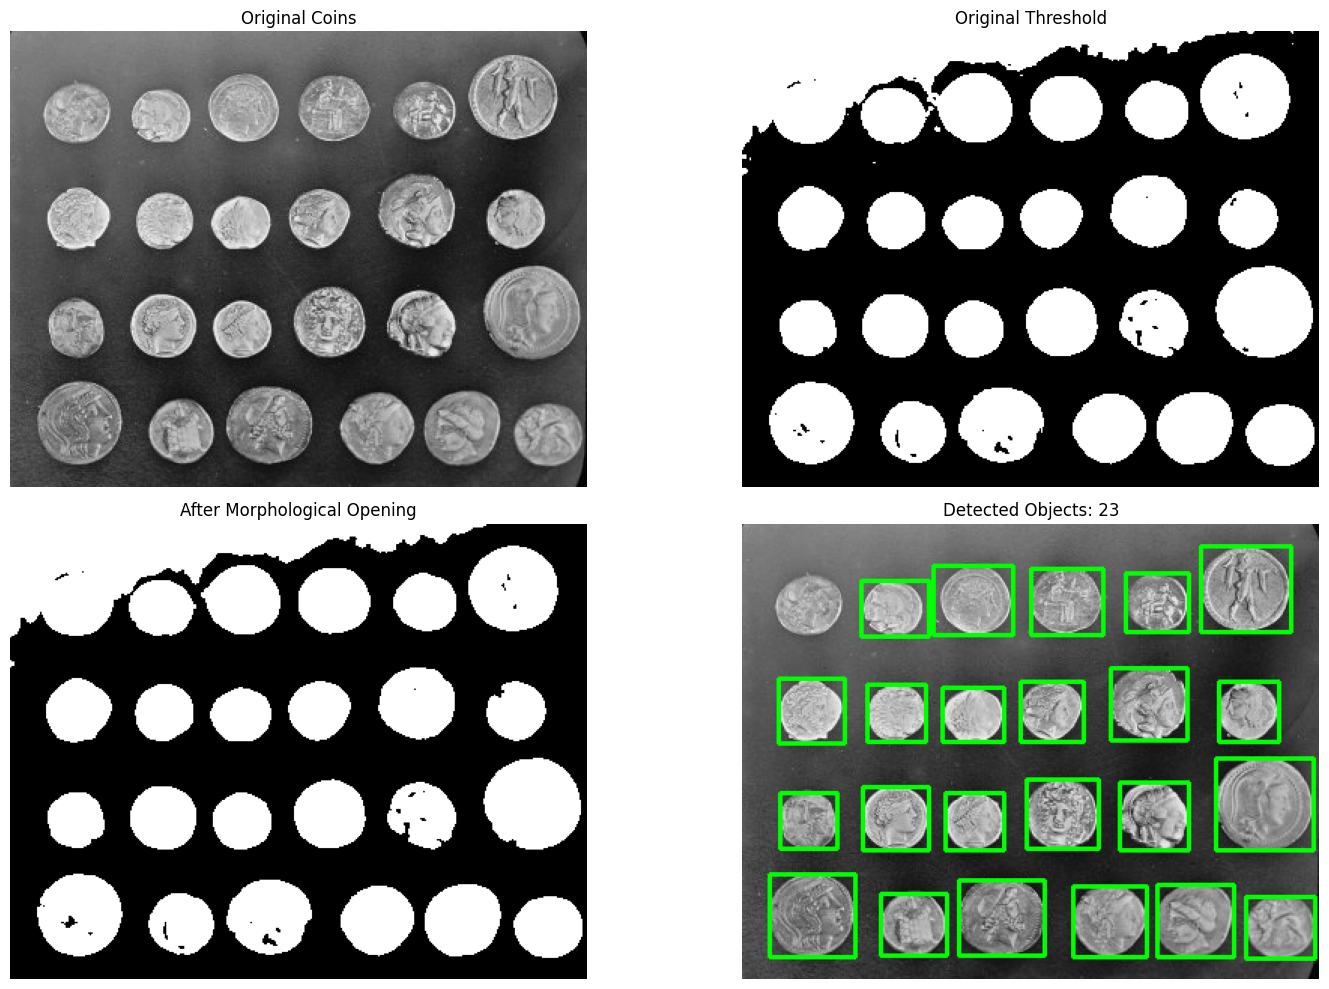

Original contours: 34
New contours: 25
Filtered objects: 23


In [11]:
# Step 1: Apply Gaussian Blur
blurred_coins = cv2.GaussianBlur(coins, (5, 5), 0)

# Step 2: Binary thresholding
_, threshold_image = cv2.threshold(
    blurred_coins,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Step 3: Create an elliptical kernel
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (5, 5)
)

# Step 4: Apply morphological opening
cleaned_image = cv2.morphologyEx(
    threshold_image,
    cv2.MORPH_OPEN,
    kernel
)

# Step 5: Find contours again
new_contours, hierarchy = cv2.findContours(
    cleaned_image,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Step 6: Filter contours
filtered_contours = []

for contour in new_contours:
    area = cv2.contourArea(contour)
    x, y, w, h = cv2.boundingRect(contour)

    # Exclude unusually large merged regions
    if area > 500 and w < 120 and h < 120:
        filtered_contours.append(contour)

# Step 7: Draw bounding boxes
count_image = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)

for contour in filtered_contours:
    x, y, w, h = cv2.boundingRect(contour)

    cv2.rectangle(
        count_image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

# Step 8: Display results
plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(coins, cmap="gray")
plt.title("Original Coins")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(threshold_image, cmap="gray")
plt.title("Original Threshold")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(cleaned_image, cmap="gray")
plt.title("After Morphological Opening")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(count_image, cv2.COLOR_BGR2RGB))
plt.title(f"Detected Objects: {len(filtered_contours)}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Original contours:", len(contours))
print("New contours:", len(new_contours))
print("Filtered objects:", len(filtered_contours))